In [1]:
!pip install osmnx==1.9.3 geopandas --quiet

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 107.2/107.2 kB 5.2 MB/s eta 0:00:00


In [2]:
import numpy as np
import random

SEED = 42
np.random.seed(SEED)
random.seed(SEED)

In [3]:
import osmnx as ox
import networkx as nx
import pandas as pd
import numpy as np
import os
from pyproj import Geod, Transformer
import matplotlib.pyplot as plt

ox.settings.log_console = True
ox.settings.use_cache = True

geod = Geod(ellps="WGS84")

print("OSMnx version:", ox.__version__)

OSMnx version: 1.9.3


In [4]:
CITY_NAME    = "Hyderabad"
ANCHOR_NAME  = "Zero Mile Stone, Nampally, Hyderabad"
CENTER_LAT   = 17.402365
CENTER_LON   = 78.468572
RADIUS_M     = 20_000
NETWORK_TYPE = "drive"
CRS_LOCK     = "EPSG:32644"   # UTM Zone 44N — correct for Hyderabad

center_point = (CENTER_LAT, CENTER_LON)

print(f"City: {CITY_NAME}")
print(f"Anchor: {ANCHOR_NAME}")
print(f"Center point (lat/lon): {center_point}")
print(f"Search radius: {RADIUS_M/1000} km")
print(f"CRS locked: {CRS_LOCK} (UTM 44N, meters)")

City: Hyderabad
Anchor: Zero Mile Stone, Nampally, Hyderabad
Center point (lat/lon): (17.402365, 78.468572)
Search radius: 20.0 km
CRS locked: EPSG:32644 (UTM 44N, meters)


In [5]:
G = ox.graph_from_point(
    center_point,
    dist=RADIUS_M,
    dist_type="bbox",
    network_type=NETWORK_TYPE,
    simplify=True
)

G = ox.project_graph(G, to_crs=CRS_LOCK)

print("Graph pulled successfully.")
print(f"Nodes: {len(G.nodes)}")
print(f"Edges: {len(G.edges)}")

Graph pulled successfully.
Nodes: 234384
Edges: 608672


In [6]:
nodes_gdf, edges_gdf = ox.graph_to_gdfs(G)
bbox_west, bbox_south, bbox_east, bbox_north = nodes_gdf.total_bounds

print("Bounding box (locked):")
print(f"  North: {bbox_north}")
print(f"  South: {bbox_south}")
print(f"  East:  {bbox_east}")
print(f"  West:  {bbox_west}")

Bounding box (locked):
  North: 1945864.1663911599
  South: 1905749.4585083674
  East:  251264.01837254057
  West:  210936.79409144464


In [7]:
output_dir = "/content/HYD_recon_survey"
os.makedirs(output_dir, exist_ok=True)

graphml_path = os.path.join(output_dir, "HYD_city.graphml")
ox.save_graphml(G, filepath=graphml_path)

city_record = {
    "city_name":            [CITY_NAME],
    "reference_point_name": [ANCHOR_NAME],
    "reference_lat":        [CENTER_LAT],
    "reference_lon":        [CENTER_LON],
    "search_radius_km":     [RADIUS_M / 1000],
    "crs":                  [CRS_LOCK],
    "bbox_north":           [bbox_north],
    "bbox_south":           [bbox_south],
    "bbox_east":            [bbox_east],
    "bbox_west":            [bbox_west],
    "node_count":           [len(G.nodes)],
    "edge_count":           [len(G.edges)],
    "network_type":         [NETWORK_TYPE],
    "graphml_file": ["HYD_city.graphml"],
}
city_df = pd.DataFrame(city_record)

city_csv_path = os.path.join(output_dir, "city.csv")
city_df.to_csv(city_csv_path, index=False)

city_df

,city_name,reference_point_name,reference_lat,reference_lon,search_radius_km,crs,bbox_north,bbox_south,bbox_east,bbox_west,node_count,edge_count,network_type,graphml_file
0,Hyderabad,"Zero Mile Stone, Nampally, Hyderabad",17.402365,78.468572,20.0,EPSG:32644,1.945864e+06,1.905749e+06,251264.018373,210936.794091,234384,608672,drive,HYD_city.graphml


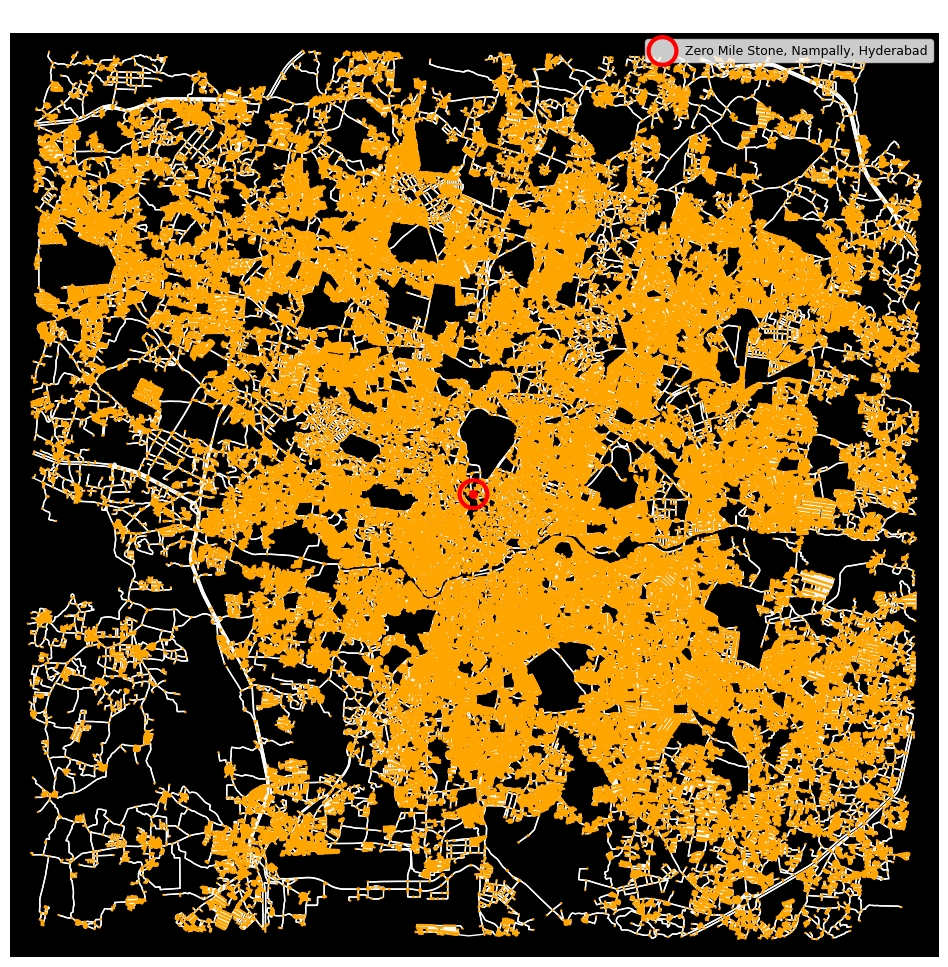

In [8]:
transformer = Transformer.from_crs("EPSG:4326", CRS_LOCK, always_xy=True)
anchor_x, anchor_y = transformer.transform(CENTER_LON, CENTER_LAT)

fig, ax = ox.plot_graph(
    G, node_size=3, node_color="orange", edge_color="white",
    bgcolor="black", figsize=(12, 12), show=False, close=False
)

ax.scatter(anchor_x, anchor_y, s=400, facecolors='none', edgecolors='red',
           linewidths=3, zorder=5, label=ANCHOR_NAME)
ax.scatter(anchor_x, anchor_y, s=30, color='red', zorder=6)

ax.set_title(f"Hyderabad Road Network — 20 km radius from Zero Mile Stone",
             color="white", fontsize=14)
ax.legend(loc='upper right', fontsize=9)
plt.show()

In [9]:
city_row = pd.read_csv(os.path.join(output_dir, "city.csv")).iloc[0]
CENTER_LAT = city_row["reference_lat"]
CENTER_LON = city_row["reference_lon"]
RADIUS_KM  = city_row["search_radius_km"]
RADIUS_M   = RADIUS_KM * 1000

print(f"Loaded center: ({CENTER_LAT}, {CENTER_LON}), radius: {RADIUS_KM} km")

Loaded center: (17.402365, 78.468572), radius: 20.0 km


In [10]:
# Hyderabad zones — hardcoded from real neighborhood centroids.
# Zone areas reflect actual neighborhood sizes, not equal pie-slice splits.
# Intra-zone delivery distance = 0.9 * sqrt(area/pi), so smaller real areas
# produce realistic ~1.5-2.5 km intra-zone distances rather than 4.5 km.

zone_areas_km2 = {
    "Secunderabad":       28.0,
    "Alwal":              35.0,
    "Miyapur":            32.0,
    "Kukatpally":         30.0,
    "Madhapur":           20.0,
    "Gachibowli":         25.0,
    "Financial District": 18.0,
    "Ameerpet":           15.0,
    "Banjara Hills":      22.0,
    "Nampally":           12.0,
    "Himayatnagar":       14.0,
    "Uppal":              30.0,
    "Vanasthalipuram":    28.0,
    "Dilsukhnagar":       20.0,
    "LB Nagar":           25.0,
    "Old City":           18.0,
}

districts_data = [
    {"district_id":  1, "district_name": "Secunderabad",       "centroid_lat": 17.4399, "centroid_lon": 78.4983, "demand_weight": 0.08},
    {"district_id":  2, "district_name": "Alwal",              "centroid_lat": 17.4726, "centroid_lon": 78.4956, "demand_weight": 0.03},
    {"district_id":  3, "district_name": "Miyapur",            "centroid_lat": 17.4955, "centroid_lon": 78.3562, "demand_weight": 0.03},
    {"district_id":  4, "district_name": "Kukatpally",         "centroid_lat": 17.4849, "centroid_lon": 78.3996, "demand_weight": 0.06},
    {"district_id":  5, "district_name": "Madhapur",           "centroid_lat": 17.4478, "centroid_lon": 78.3915, "demand_weight": 0.12},
    {"district_id":  6, "district_name": "Gachibowli",         "centroid_lat": 17.4401, "centroid_lon": 78.3489, "demand_weight": 0.08},
    {"district_id":  7, "district_name": "Financial District", "centroid_lat": 17.4156, "centroid_lon": 78.3412, "demand_weight": 0.05},
    {"district_id":  8, "district_name": "Ameerpet",           "centroid_lat": 17.4374, "centroid_lon": 78.4487, "demand_weight": 0.08},
    {"district_id":  9, "district_name": "Banjara Hills",      "centroid_lat": 17.4156, "centroid_lon": 78.4480, "demand_weight": 0.10},
    {"district_id": 10, "district_name": "Nampally",           "centroid_lat": 17.3850, "centroid_lon": 78.4700, "demand_weight": 0.07},
    {"district_id": 11, "district_name": "Himayatnagar",       "centroid_lat": 17.3980, "centroid_lon": 78.4850, "demand_weight": 0.07},
    {"district_id": 12, "district_name": "Uppal",              "centroid_lat": 17.4050, "centroid_lon": 78.5590, "demand_weight": 0.06},
    {"district_id": 13, "district_name": "Vanasthalipuram",    "centroid_lat": 17.3380, "centroid_lon": 78.5530, "demand_weight": 0.02},
    {"district_id": 14, "district_name": "Dilsukhnagar",       "centroid_lat": 17.3688, "centroid_lon": 78.5267, "demand_weight": 0.07},
    {"district_id": 15, "district_name": "LB Nagar",           "centroid_lat": 17.3450, "centroid_lon": 78.5480, "demand_weight": 0.04},
    {"district_id": 16, "district_name": "Old City",           "centroid_lat": 17.3600, "centroid_lon": 78.4740, "demand_weight": 0.07},
]

weight_check = sum(d["demand_weight"] for d in districts_data)
print(f"Sum of demand weights: {weight_check:.6f}")
assert abs(weight_check - 1.0) < 1e-6, "Weights must sum to 1.0"

districts_df = pd.DataFrame(districts_data)
districts_df["area_km2"] = districts_df["district_name"].map(zone_areas_km2)

# Verify intra-zone delivery distances are realistic
districts_df["zone_radius_km"]    = np.sqrt(districts_df["area_km2"] / np.pi)
districts_df["intra_zone_dist_km"] = 0.9 * districts_df["zone_radius_km"]
print(f"\nIntra-zone distance range: {districts_df['intra_zone_dist_km'].min():.2f} — {districts_df['intra_zone_dist_km'].max():.2f} km")
print(f"Intra-zone distance mean:  {districts_df['intra_zone_dist_km'].mean():.2f} km  (target: ~1.5-2.5 km)")
print(f"Total zones: {len(districts_df)}")
districts_df[["district_id", "district_name", "area_km2", "intra_zone_dist_km", "demand_weight"]]


Sum of demand weights: 1.000000

Zone area (equal split): 78.54 km² per zone
Total zones: 16


,district_id,district_name,demand_weight
0,1,Secunderabad,0.08
1,2,Alwal,0.03
2,3,Miyapur,0.03
3,4,Kukatpally,0.06
4,5,Madhapur,0.12
5,6,Gachibowli,0.08
6,7,Financial District,0.05
7,8,Ameerpet,0.08
8,9,Banjara Hills,0.10
9,10,Nampally,0.07


In [11]:
districts_csv_path = os.path.join(output_dir, "districts.csv")
districts_df.to_csv(districts_csv_path, index=False)

print(f"Saved to: {districts_csv_path}")
districts_df

Saved to: /content/HYD_recon_survey/HYD_districts.csv


,district_id,district_name,centroid_lat,centroid_lon,demand_weight,area_km2
0,1,Secunderabad,17.4399,78.4983,0.08,78.54
1,2,Alwal,17.4726,78.4956,0.03,78.54
2,3,Miyapur,17.4955,78.3562,0.03,78.54
3,4,Kukatpally,17.4849,78.3996,0.06,78.54
4,5,Madhapur,17.4478,78.3915,0.12,78.54
5,6,Gachibowli,17.4401,78.3489,0.08,78.54
6,7,Financial District,17.4156,78.3412,0.05,78.54
7,8,Ameerpet,17.4374,78.4487,0.08,78.54
8,9,Banjara Hills,17.4156,78.4480,0.10,78.54
9,10,Nampally,17.3850,78.4700,0.07,78.54


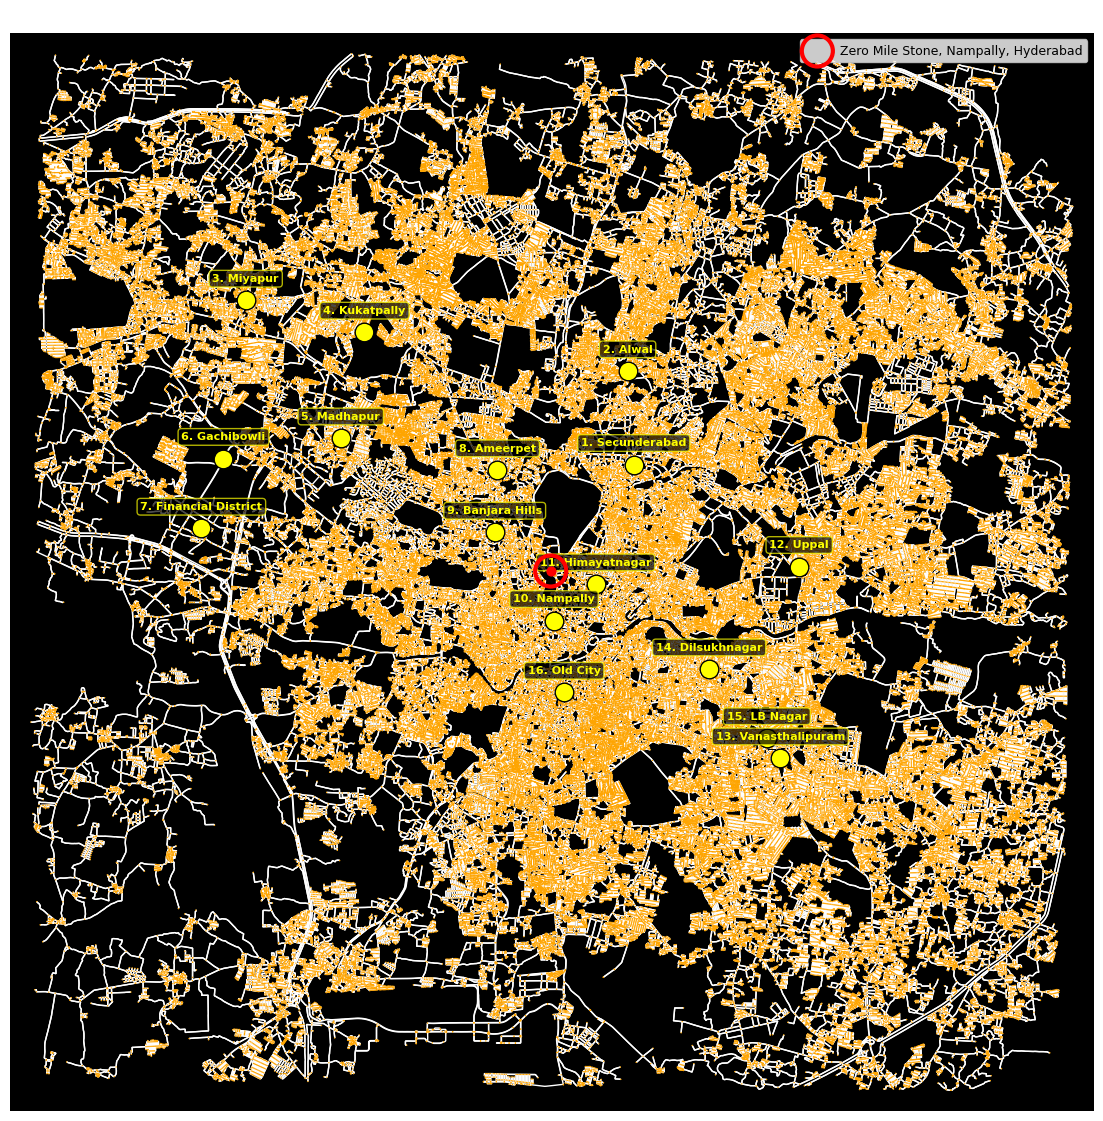

In [12]:
graphml_path = os.path.join(output_dir, "HYD_city.graphml")
G = ox.load_graphml(graphml_path)

transformer = Transformer.from_crs("EPSG:4326", CRS_LOCK, always_xy=True)
anchor_x, anchor_y = transformer.transform(CENTER_LON, CENTER_LAT)

fig, ax = ox.plot_graph(
    G, node_size=1, node_color="orange", edge_color="white",
    bgcolor="black", figsize=(14, 14), show=False, close=False
)

for _, row in districts_df.iterrows():
    dx, dy = transformer.transform(row["centroid_lon"], row["centroid_lat"])
    ax.scatter(dx, dy, s=180, color='yellow', edgecolors='black', zorder=6)
    ax.annotate(
        f"{row['district_id']}. {row['district_name']}",
        (dx, dy), color='yellow', fontsize=8, fontweight='bold',
        ha='center', va='bottom', xytext=(0, 12),
        textcoords='offset points', zorder=7,
        bbox=dict(boxstyle="round,pad=0.3", facecolor='black',
                  edgecolor='yellow', alpha=0.7)
    )

ax.scatter(anchor_x, anchor_y, s=500, facecolors='none', edgecolors='red',
           linewidths=3, zorder=8, label=ANCHOR_NAME)
ax.scatter(anchor_x, anchor_y, s=40, color='red', zorder=9)


ax.set_title("Hyderabad — 16 Zones from Zero Mile Stone (20 km radius)",
             color="white", fontsize=14)
ax.legend(loc='upper right', fontsize=9)
plt.show()

In [13]:
np.random.seed(42)

districts_df = pd.read_csv(os.path.join(output_dir, "districts.csv"))

print(f"Loaded {len(districts_df)} zones")
districts_df[["district_id", "district_name", "demand_weight"]]

Loaded 16 zones


,district_id,district_name,demand_weight
0,1,Secunderabad,0.08
1,2,Alwal,0.03
2,3,Miyapur,0.03
3,4,Kukatpally,0.06
4,5,Madhapur,0.12
5,6,Gachibowli,0.08
6,7,Financial District,0.05
7,8,Ameerpet,0.08
8,9,Banjara Hills,0.10
9,10,Nampally,0.07


In [14]:
small_restaurants = pd.DataFrame({
    "restaurant_id": [f"R-S-{i+1:03d}" for i in range(402)],
    "size_tier": "small",
})
print(f"Small restaurants registered: {len(small_restaurants)}")
small_restaurants.head()

Small restaurants registered: 402


,restaurant_id,size_tier
0,R-S-001,small
1,R-S-002,small
2,R-S-003,small
3,R-S-004,small
4,R-S-005,small


In [15]:
medium_restaurants = pd.DataFrame({
    "restaurant_id": [f"R-M-{i+1:03d}" for i in range(624)],
    "size_tier": "medium",
})
print(f"Medium restaurants registered: {len(medium_restaurants)}")
medium_restaurants.head()

Medium restaurants registered: 624


,restaurant_id,size_tier
0,R-M-001,medium
1,R-M-002,medium
2,R-M-003,medium
3,R-M-004,medium
4,R-M-005,medium


In [16]:
large_restaurants = pd.DataFrame({
    "restaurant_id": [f"R-L-{i+1:03d}" for i in range(474)],
    "size_tier": "large",
})
print(f"Large restaurants registered: {len(large_restaurants)}")

restaurants_df = pd.concat([small_restaurants, medium_restaurants, large_restaurants], ignore_index=True)

print(f"\nTotal restaurants: {len(restaurants_df)}")
assert len(restaurants_df) == 1500, "Restaurant count must equal 1500"
restaurants_df["size_tier"].value_counts()

Large restaurants registered: 474

Total restaurants: 1500


,count
size_tier,
medium,624
large,474
small,402


In [17]:
zone_ids = districts_df["district_id"].values
zone_weights = districts_df["demand_weight"].values

restaurants_df["zone_id"] = np.random.choice(zone_ids, size=len(restaurants_df), p=zone_weights)

zone_name_lookup = districts_df.set_index("district_id")["district_name"]
restaurants_df["zone_name"] = restaurants_df["zone_id"].map(zone_name_lookup)

print("Restaurant count per zone:")
print(restaurants_df.groupby(["zone_id", "zone_name"]).size().sort_values(ascending=False))

Restaurant count per zone:
zone_id  zone_name         
5        Madhapur              163
9        Banjara Hills         152
1        Secunderabad          126
6        Gachibowli            123
14       Dilsukhnagar          115
10       Nampally              114
8        Ameerpet              114
12       Uppal                  94
4        Kukatpally             93
11       Himayatnagar           80
16       Old City               77
7        Financial District     62
3        Miyapur                55
15       LB Nagar               51
2        Alwal                  49
13       Vanasthalipuram        32
dtype: int64


In [18]:
prep_time_ranges = {
    "small":  (10, 15),
    "medium": (15, 25),
    "large":  (20, 30),
}

def assign_prep_time(tier):
    low, high = prep_time_ranges[tier]
    return np.random.randint(low, high + 1)

restaurants_df["prep_time_min"] = restaurants_df["size_tier"].apply(assign_prep_time)

print("Prep time summary by tier:")
restaurants_df.groupby("size_tier")["prep_time_min"].agg(["min", "max", "mean"])

Prep time summary by tier:


,min,max,mean
size_tier,,,
large,20,30,24.742616
medium,15,25,20.003205
small,10,15,12.639303


In [19]:
restaurants_df = restaurants_df[["restaurant_id", "size_tier", "zone_id", "zone_name", "prep_time_min"]]

restaurants_csv_path = os.path.join(output_dir, "restaurants.csv")
restaurants_df.to_csv(restaurants_csv_path, index=False)

print(f"Saved to: {restaurants_csv_path}")
print(f"Total restaurants: {len(restaurants_df)}")
restaurants_df

Saved to: /content/HYD_recon_survey/HYD_restaurants.csv
Total restaurants: 1500


,restaurant_id,size_tier,zone_id,zone_name,prep_time_min
0,R-S-001,small,6,Gachibowli,11
1,R-S-002,small,16,Old City,15
2,R-S-003,small,11,Himayatnagar,13
3,R-S-004,small,9,Banjara Hills,14
4,R-S-005,small,4,Kukatpally,14
...,...,...,...,...,...
1495,R-L-470,large,10,Nampally,25
1496,R-L-471,large,9,Banjara Hills,21
1497,R-L-472,large,8,Ameerpet,27
1498,R-L-473,large,6,Gachibowli,20


In [20]:
expected_pct = {z["district_name"]: z["demand_weight"] * 100 for z in districts_df.to_dict("records")}

actual_counts = restaurants_df["zone_name"].value_counts()
actual_pct = (actual_counts / len(restaurants_df) * 100).round(1)

comparison = pd.DataFrame({
    "expected_%": pd.Series(expected_pct).round(1),
    "actual_%": actual_pct
}).fillna(0)

print(comparison)
print(f"\nTotal restaurants: {len(restaurants_df)} (expected 1500)")

assert len(restaurants_df) == 1500
assert (restaurants_df["size_tier"] == "small").sum() == 402
assert (restaurants_df["size_tier"] == "medium").sum() == 624
assert (restaurants_df["size_tier"] == "large").sum() == 474

for tier, (low, high) in prep_time_ranges.items():
    tier_data = restaurants_df[restaurants_df["size_tier"] == tier]["prep_time_min"]
    within_bounds = tier_data.between(low, high).all()
    print(f"{tier}: prep_time within [{low},{high}]? {within_bounds}")

print("\n✅ All restaurant checks passed.")

                    expected_%  actual_%
Alwal                      3.0       3.3
Ameerpet                   8.0       7.6
Banjara Hills             10.0      10.1
Dilsukhnagar               7.0       7.7
Financial District         5.0       4.1
Gachibowli                 8.0       8.2
Himayatnagar               6.0       5.3
Kukatpally                 6.0       6.2
LB Nagar                   3.0       3.4
Madhapur                  12.0      10.9
Miyapur                    3.0       3.7
Nampally                   7.0       7.6
Old City                   5.0       5.1
Secunderabad               8.0       8.4
Uppal                      6.0       6.3
Vanasthalipuram            3.0       2.1

Total restaurants: 1500 (expected 1500)
small: prep_time within [10,15]? True
medium: prep_time within [15,25]? True
large: prep_time within [20,30]? True

✅ All restaurant checks passed.


In [21]:
np.random.seed(11)

restaurants_df = pd.read_csv(os.path.join(output_dir, "restaurants.csv"))

tier_alpha = {"small": 1.0, "medium": 2.0, "large": 3.5}

raw_weights = restaurants_df["size_tier"].map(tier_alpha).apply(
    lambda a: np.random.gamma(shape=a, scale=1.0)
)

restaurants_df["popularity_weight"] = raw_weights / raw_weights.sum()

weight_check = restaurants_df["popularity_weight"].sum()
print(f"Sum of popularity_weight: {weight_check:.6f}")
assert abs(weight_check - 1.0) < 1e-6, "popularity_weight must sum to 1.0"

restaurants_df.groupby("size_tier")["popularity_weight"].agg(["min", "max", "mean", "sum"])

Sum of popularity_weight: 1.000000


,min,max,mean,sum
size_tier,,,,
large,1.031556e-04,0.003174,0.001062,0.503506
medium,1.591543e-05,0.002444,0.000600,0.374491
small,9.234024e-07,0.001649,0.000303,0.122002


In [22]:
import json

PEAK_HOURS  = [12, 13, 19, 20, 21]
NIGHT_HOURS = [22, 23]

# Partners — supply-side, national partner density anchor
# National partner density = 475,000 / 61,111 km² = 7.772/km²
# peak: ×650 ×0.50 ×0.38 = 961
# normal: peak ×0.565 = 543, night: peak ×0.350 = 336

simulation_config = {
    "active_partners_normal": 543,
    "active_partners_peak":   961,
    "active_partners_night":  336,
    "peak_hours":             PEAK_HOURS,
    "night_hours":            NIGHT_HOURS,
    "max_orders_per_trip":    3,
    "fleet_motorcycle_pct":   1.0,
    "fleet_bike_pct":         0.0,
}

assert abs(simulation_config["fleet_motorcycle_pct"] + simulation_config["fleet_bike_pct"] - 1.0) < 1e-6, \
    "Fleet percentages must sum to 1.0"

config_path = os.path.join(output_dir, "simulation_config.json")
with open(config_path, "w") as f:
    json.dump(simulation_config, f, indent=2)

print(f"Saved to: {config_path}")
print(json.dumps(simulation_config, indent=2))

Saved to: /content/HYD_recon_survey/HYD_simulation_config.json
{
  "active_partners_normal": 543,
  "active_partners_peak": 961,
  "active_partners_night": 336,
  "peak_hours": [
    12,
    13,
    19,
    20,
    21
  ],
  "night_hours": [
    22,
    23
  ],
  "max_orders_per_trip": 3,
  "fleet_motorcycle_pct": 1.0,
  "fleet_bike_pct": 0.0
}


In [23]:
restaurants_csv_path = os.path.join(output_dir, "restaurants.csv")
restaurants_df.to_csv(restaurants_csv_path, index=False)

print(f"Saved to: {restaurants_csv_path}")
print(f"Total restaurants: {len(restaurants_df)}")
restaurants_df

Saved to: /content/HYD_recon_survey/HYD_restaurants.csv
Total restaurants: 1500


,restaurant_id,size_tier,zone_id,zone_name,prep_time_min,popularity_weight
0,R-S-001,small,6,Gachibowli,11,0.000060
1,R-S-002,small,16,Old City,15,0.000006
2,R-S-003,small,11,Himayatnagar,13,0.000187
3,R-S-004,small,9,Banjara Hills,14,0.000388
4,R-S-005,small,4,Kukatpally,14,0.000164
...,...,...,...,...,...,...
1495,R-L-470,large,10,Nampally,25,0.001278
1496,R-L-471,large,9,Banjara Hills,21,0.002006
1497,R-L-472,large,8,Ameerpet,27,0.001157
1498,R-L-473,large,6,Gachibowli,20,0.000494


In [24]:
assert "popularity_weight" in restaurants_df.columns
assert abs(restaurants_df["popularity_weight"].sum() - 1.0) < 1e-6
assert len(restaurants_df) == 1500, f"Expected 1500 restaurants, found {len(restaurants_df)}"

with open(config_path) as f:
    loaded_config = json.load(f)

assert loaded_config["active_partners_normal"] == 543
assert loaded_config["active_partners_peak"]   == 961
assert loaded_config["active_partners_night"]  == 336
assert loaded_config["max_orders_per_trip"]    == 3
assert loaded_config["fleet_motorcycle_pct"]   == 1.0
assert loaded_config["fleet_bike_pct"]         == 0.0
assert "HYD_partners.csv" not in os.listdir(output_dir), \
    "No partners.csv should exist — partners are a capacity constraint, not entities"

print("✅ All Day 4 checks passed.")
print(f"Files in {output_dir}: {os.listdir(output_dir)}")

✅ All Day 4 checks passed.
Files in /content/HYD_recon_survey: ['HYD_restaurants.csv', 'HYD_simulation_config.json', 'HYD_city.csv', 'HYD_districts.csv', 'HYD_city.graphml']


In [25]:
np.random.seed(21)

districts_df   = pd.read_csv(os.path.join(output_dir, "districts.csv"))
restaurants_df = pd.read_csv(os.path.join(output_dir, "restaurants.csv"))

ORDER_WINDOW_START_HOUR = 10
ORDER_WINDOW_END_HOUR   = 24

# Orders — demand-side, national order density anchor
# National order density = 2.36M / 61,111 km² = 38.65/km²/day
# orders/day: ×650 ×3.056 ×0.50 ×0.38 ×1.09 = 15,900
# baseline orders/hr: 15,900 ×39% ÷ 8 = 775
# spike low: peak avg ×0.90 = 1,746, spike high: peak avg ×1.10 = 2,134
BASELINE_ORDERS_PER_HOUR = 775

LUNCH_SPIKE_HOURS  = [12, 13]
DINNER_SPIKE_HOURS = [19, 20, 21]
NIGHT_HOURS        = [22, 23]

SPIKE_RATE_LOW  = 1746
SPIKE_RATE_HIGH = 2134

hours = list(range(ORDER_WINDOW_START_HOUR, ORDER_WINDOW_END_HOUR))

hourly_rate = {}
for h in hours:
    if h in LUNCH_SPIKE_HOURS or h in DINNER_SPIKE_HOURS:
        hourly_rate[h] = int(np.random.randint(SPIKE_RATE_LOW, SPIKE_RATE_HIGH + 1))
    else:
        hourly_rate[h] = BASELINE_ORDERS_PER_HOUR

expected_total = sum(hourly_rate.values())

print("Hourly order-rate profile:")
for h, r in hourly_rate.items():
    tag = "LUNCH SPIKE" if h in LUNCH_SPIKE_HOURS else ("DINNER SPIKE" if h in DINNER_SPIKE_HOURS else "")
    print(f"  {h:02d}:00  ->  {r:5d} orders/hr  {tag}")

print(f"\nExpected total orders: {expected_total:.0f}")

Hourly order-rate profile:
  10:00  ->    775 orders/hr  
  11:00  ->    775 orders/hr  
  12:00  ->   1953 orders/hr  LUNCH SPIKE
  13:00  ->   2058 orders/hr  LUNCH SPIKE
  14:00  ->    775 orders/hr  
  15:00  ->    775 orders/hr  
  16:00  ->    775 orders/hr  
  17:00  ->    775 orders/hr  
  18:00  ->    775 orders/hr  
  19:00  ->   2006 orders/hr  DINNER SPIKE
  20:00  ->   1794 orders/hr  DINNER SPIKE
  21:00  ->   2114 orders/hr  DINNER SPIKE
  22:00  ->    775 orders/hr  
  23:00  ->    775 orders/hr  

Expected total orders: 16900


In [26]:
order_rows = []
order_counter = 1

for h in hours:
    rate = hourly_rate[h]
    n_orders_this_hour = np.random.poisson(rate)

    seconds_in_hour = np.random.randint(0, 3600, size=n_orders_this_hour)
    timestamps = h * 3600 + seconds_in_hour

    for ts in timestamps:
        order_rows.append({
            "order_id": f"O-{order_counter:06d}",
            "timestamp_sec": int(ts),
        })
        order_counter += 1

orders_df = pd.DataFrame(order_rows).sort_values("timestamp_sec").reset_index(drop=True)

print(f"Total orders generated: {len(orders_df)}")
orders_df.head()

Total orders generated: 16856


,order_id,timestamp_sec
0,O-000218,36000
1,O-000087,36005
2,O-000472,36007
3,O-000073,36008
4,O-000446,36011


In [27]:
orders_df["restaurant_id"] = np.random.choice(
    restaurants_df["restaurant_id"].values,
    size=len(orders_df),
    p=restaurants_df["popularity_weight"].values
)

INTRA_ZONE_BIAS = 0.90   # 90% orders stay within same zone — Tier 1 density justified

restaurant_zone_lookup = restaurants_df.set_index("restaurant_id")["zone_id"]
orders_df["_restaurant_zone_id"] = orders_df["restaurant_id"].map(restaurant_zone_lookup)

is_intra = np.random.random(len(orders_df)) < INTRA_ZONE_BIAS

dest_zone_ids = np.empty(len(orders_df), dtype=int)
dest_zone_ids[is_intra] = orders_df.loc[is_intra, "_restaurant_zone_id"].values

zone_ids_arr = districts_df["district_id"].values
demand_w     = districts_df.set_index("district_id")["demand_weight"]
centroid_lut = districts_df.set_index("district_id")[["centroid_lat", "centroid_lon"]]

def geodesic_km(z1, z2):
    lat1, lon1 = centroid_lut.loc[z1]
    lat2, lon2 = centroid_lut.loc[z2]
    _, _, dist_m = geod.inv(lon1, lat1, lon2, lat2)
    return dist_m / 1000

# Inter-zone distance caps — grounded in Hyderabad geography:
# near     = centroid distance < 8 km  → 90% of inter-zone share
# far      = centroid distance 8-12 km → 10% of inter-zone share
# excluded = centroid distance > 12 km → 0%  (no cross-city orders)
NEAR_CAP_KM = 8.0
FAR_CAP_KM  = 12.0
NEAR_SHARE  = 0.90
FAR_SHARE   = 0.10

for rz in orders_df.loc[~is_intra, "_restaurant_zone_id"].unique():
    mask = (~is_intra) & (orders_df["_restaurant_zone_id"] == rz)
    n    = mask.sum()

    other_zones = [z for z in zone_ids_arr if z != rz]
    near_zones  = [z for z in other_zones if geodesic_km(rz, z) <  NEAR_CAP_KM]
    far_zones   = [z for z in other_zones if NEAR_CAP_KM <= geodesic_km(rz, z) <= FAR_CAP_KM]

    if not near_zones:
        near_zones = other_zones  # fallback: use all zones if none within 8 km

    if not far_zones:
        pool       = near_zones
        combined_w = demand_w.loc[near_zones]
        combined_w = combined_w / combined_w.sum()
    else:
        near_w = demand_w.loc[near_zones] / demand_w.loc[near_zones].sum() * NEAR_SHARE
        far_w  = demand_w.loc[far_zones]  / demand_w.loc[far_zones].sum()  * FAR_SHARE
        pool   = near_zones + far_zones
        combined_w = pd.concat([near_w, far_w]).reindex(pool)
        combined_w = combined_w / combined_w.sum()  # normalize — safety

    dest_zone_ids[mask.values] = np.random.choice(pool, size=n, p=combined_w.values)

orders_df["destination_zone_id"] = dest_zone_ids
orders_df = orders_df.drop(columns=["_restaurant_zone_id"])
orders_df = orders_df[["order_id", "timestamp_sec", "restaurant_id", "destination_zone_id"]]

print(f"Intra-zone orders:  {is_intra.sum()} ({is_intra.mean()*100:.1f}%)")
print(f"Inter-zone orders:  {(~is_intra).sum()} ({(~is_intra).mean()*100:.1f}%)")

# Verify distance distribution of inter-zone orders
inter_df = orders_df[~is_intra].copy()
inter_df["_rz"] = inter_df["restaurant_id"].map(
    restaurants_df.set_index("restaurant_id")["zone_id"]
)
inter_df["_dist_km"] = inter_df.apply(
    lambda r: geodesic_km(r["_rz"], r["destination_zone_id"]), axis=1
)
print(f"\nInter-zone distance distribution:")
print(f"  < 8 km  : {(inter_df['_dist_km'] < 8).mean()*100:.1f}%  (target 90%)")
print(f"  8-12 km : {inter_df['_dist_km'].between(8, 12).mean()*100:.1f}%  (target 10%)")
print(f"  > 12 km : {(inter_df['_dist_km'] > 12).mean()*100:.1f}%  (target  0%)")

orders_df.head()


Intra-zone orders: 15125 (89.7%)
Inter-zone orders: 1731 (10.3%)


,order_id,timestamp_sec,restaurant_id,destination_zone_id
0,O-000218,36000,R-L-154,9
1,O-000087,36005,R-L-289,8
2,O-000472,36007,R-S-004,9
3,O-000073,36008,R-S-347,10
4,O-000446,36011,R-M-593,6


Saved to: /content/HYD_recon_survey/HYD_orders.csv
Total orders: 16856


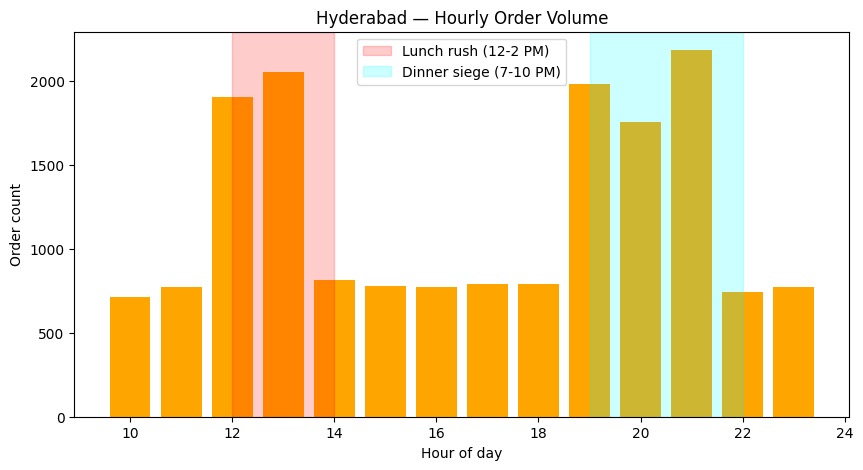

In [28]:
orders_csv_path = os.path.join(output_dir, "orders.csv")
orders_df.to_csv(orders_csv_path, index=False)

print(f"Saved to: {orders_csv_path}")
print(f"Total orders: {len(orders_df)}")

orders_df["hour"] = orders_df["timestamp_sec"] // 3600
hourly_counts = orders_df["hour"].value_counts().sort_index()

fig, ax = plt.subplots(figsize=(10, 5))
ax.bar(hourly_counts.index, hourly_counts.values, color="orange")
ax.axvspan(12, 14, color="red", alpha=0.2, label="Lunch rush (12-2 PM)")
ax.axvspan(19, 22, color="cyan", alpha=0.2, label="Dinner siege (7-10 PM)")
ax.set_xlabel("Hour of day")
ax.set_ylabel("Order count")
ax.set_title("Hyderabad — Hourly Order Volume")
ax.legend()
plt.show()

orders_df = orders_df.drop(columns=["hour"])

In [29]:
assert "orders.csv" in os.listdir(output_dir)
assert set(orders_df.columns) == {"order_id", "timestamp_sec", "restaurant_id", "destination_zone_id"}
assert orders_df["order_id"].is_unique, "order_id must be unique"

min_ts = ORDER_WINDOW_START_HOUR * 3600
max_ts = ORDER_WINDOW_END_HOUR * 3600
assert orders_df["timestamp_sec"].between(min_ts, max_ts).all()

assert orders_df["restaurant_id"].isin(restaurants_df["restaurant_id"]).all()
assert orders_df["destination_zone_id"].isin(districts_df["district_id"]).all()

low_bound  = expected_total * 0.90
high_bound = expected_total * 1.10
total_orders = len(orders_df)
assert low_bound <= total_orders <= high_bound, \
    f"Total orders {total_orders} outside expected range [{low_bound:.0f}, {high_bound:.0f}]"

print(f"✅ All Day 5 checks passed. Total orders: {total_orders}")
print(f"Files in {output_dir}: {os.listdir(output_dir)}")

✅ All Day 5 checks passed. Total orders: 16856
Files in /content/HYD_recon_survey: ['HYD_restaurants.csv', 'HYD_simulation_config.json', 'HYD_orders.csv', 'HYD_city.csv', 'HYD_districts.csv', 'HYD_city.graphml']


In [30]:
np.random.seed(33)

orders_df      = pd.read_csv(os.path.join(output_dir, "orders.csv"))
restaurants_df = pd.read_csv(os.path.join(output_dir, "restaurants.csv"))
districts_df   = pd.read_csv(os.path.join(output_dir, "districts.csv"))

prep_time_lookup = restaurants_df.set_index("restaurant_id")["prep_time_min"]
orders_df["prep_time_min"] = orders_df["restaurant_id"].map(prep_time_lookup)
orders_df["estimated_ready_sec"] = orders_df["timestamp_sec"] + orders_df["prep_time_min"] * 60

print("estimated_ready_sec computed.")
orders_df[["order_id", "timestamp_sec", "restaurant_id", "prep_time_min", "estimated_ready_sec"]].head()

estimated_ready_sec computed.


,order_id,timestamp_sec,restaurant_id,prep_time_min,estimated_ready_sec
0,O-000218,36000,R-L-154,26,37560
1,O-000087,36005,R-L-289,21,37265
2,O-000472,36007,R-S-004,14,36847
3,O-000073,36008,R-S-347,13,36788
4,O-000446,36011,R-M-593,23,37391


In [31]:
SLA_WINDOW_SEC = 2100

orders_df["sla_deadline_sec"] = orders_df["timestamp_sec"] + SLA_WINDOW_SEC

print(f"sla_deadline_sec = timestamp_sec + {SLA_WINDOW_SEC}")
orders_df[["order_id", "timestamp_sec", "sla_deadline_sec"]].head()

sla_deadline_sec = timestamp_sec + 2100


,order_id,timestamp_sec,sla_deadline_sec
0,O-000218,36000,38100
1,O-000087,36005,38105
2,O-000472,36007,38107
3,O-000073,36008,38108
4,O-000446,36011,38111


In [32]:
ORDER_VALUE_MEAN_INR = 379
ORDER_VALUE_MIN_INR  = 150

sigma = 0.5
mu = np.log(ORDER_VALUE_MEAN_INR) - (sigma ** 2) / 2

raw_values = np.random.lognormal(mean=mu, sigma=sigma, size=len(orders_df))
orders_df["order_value_inr"] = np.clip(raw_values, ORDER_VALUE_MIN_INR, None).round(2)

print(f"order_value_inr — mean: {orders_df['order_value_inr'].mean():.2f}, "
      f"min: {orders_df['order_value_inr'].min():.2f}, max: {orders_df['order_value_inr'].max():.2f}")
orders_df[["order_id", "order_value_inr"]].head()

order_value_inr — mean: 381.52, min: 150.00, max: 2520.85


,order_id,order_value_inr
0,O-000218,285.18
1,O-000087,150.06
2,O-000472,155.23
3,O-000073,251.47
4,O-000446,300.12


In [33]:
orders_df["hour"] = orders_df["timestamp_sec"] // 3600

def label_peak_window(h):
    if h in LUNCH_SPIKE_HOURS:
        return "lunch"
    elif h in DINNER_SPIKE_HOURS:
        return "dinner"
    else:
        return "offpeak"

orders_df["peak_window"] = orders_df["hour"].apply(label_peak_window)

print("peak_window distribution:")
print(orders_df["peak_window"].value_counts())
orders_df = orders_df.drop(columns=["hour"])

peak_window distribution:
peak_window
offpeak    6962
dinner     5928
lunch      3966
Name: count, dtype: int64


In [34]:
BATCH_WINDOW_SEC = 120  # midpoint of literature-cited 60-180s range (Agatz 2011, Reyes 2018, Ulmer 2021)

print(f"BATCH_WINDOW_SEC = {BATCH_WINDOW_SEC}s")

BATCH_WINDOW_SEC = 120s


In [35]:
def _diagnostic_batchable_pct(df, window_sec):
    sorted_df = df.sort_values(["restaurant_id", "destination_zone_id", "timestamp_sec"]).reset_index(drop=True)
    flags = np.zeros(len(sorted_df), dtype=int)

    for _, group in sorted_df.groupby(["restaurant_id", "destination_zone_id"]):
        ts = group["timestamp_sec"].values
        if len(ts) < 2:
            continue
        idx = group.index.values
        gap_prev = np.diff(ts, prepend=ts[0] - window_sec - 1)
        gap_next = np.diff(ts, append=ts[-1] + window_sec + 1)
        flags[idx] = ((gap_prev <= window_sec) | (gap_next <= window_sec)).astype(int)

    return flags.mean() * 100

_pct = _diagnostic_batchable_pct(orders_df, BATCH_WINDOW_SEC)
print(f"[diagnostic only] Theoretical batchability at BATCH_WINDOW_SEC={BATCH_WINDOW_SEC}s: {_pct:.2f}%")
print("(Not saved — for reference only.)")

[diagnostic only] Theoretical batchability at BATCH_WINDOW_SEC=120s: 8.22%
(Not saved — for reference only.)


In [36]:
config_path = os.path.join(output_dir, "simulation_config.json")
with open(config_path) as f:
    simulation_config = json.load(f)

simulation_config["batch_window_sec"] = BATCH_WINDOW_SEC

with open(config_path, "w") as f:
    json.dump(simulation_config, f, indent=2)

print(f"Updated simulation_config.json with batch_window_sec = {BATCH_WINDOW_SEC}")
print(json.dumps(simulation_config, indent=2))

Updated HYD_simulation_config.json with batch_window_sec = 120
{
  "active_partners_normal": 543,
  "active_partners_peak": 961,
  "active_partners_night": 336,
  "peak_hours": [
    12,
    13,
    19,
    20,
    21
  ],
  "night_hours": [
    22,
    23
  ],
  "max_orders_per_trip": 3,
  "fleet_motorcycle_pct": 1.0,
  "fleet_bike_pct": 0.0,
  "batch_window_sec": 120
}


In [37]:
orders_csv_path = os.path.join(output_dir, "orders.csv")
orders_df.to_csv(orders_csv_path, index=False)

assert "estimated_ready_sec" in orders_df.columns
assert "sla_deadline_sec" in orders_df.columns
assert "order_value_inr" in orders_df.columns
assert "peak_window" in orders_df.columns

assert (orders_df["estimated_ready_sec"] == orders_df["timestamp_sec"] + orders_df["prep_time_min"] * 60).all()
assert (orders_df["sla_deadline_sec"] == orders_df["timestamp_sec"] + 2100).all()
assert (orders_df["order_value_inr"] >= 150).all(), "order_value_inr must respect the ₹150 floor"
assert set(orders_df["peak_window"].unique()) <= {"lunch", "dinner", "offpeak"}

print("✅ All Day 6 checks passed.")
print(f"Saved to: {orders_csv_path}")
orders_df.head()

✅ All Day 6 checks passed.
Saved to: /content/HYD_recon_survey/HYD_orders.csv


,order_id,timestamp_sec,restaurant_id,destination_zone_id,prep_time_min,estimated_ready_sec,sla_deadline_sec,order_value_inr,peak_window
0,O-000218,36000,R-L-154,9,26,37560,38100,285.18,offpeak
1,O-000087,36005,R-L-289,8,21,37265,38105,150.06,offpeak
2,O-000472,36007,R-S-004,9,14,36847,38107,155.23,offpeak
3,O-000073,36008,R-S-347,10,13,36788,38108,251.47,offpeak
4,O-000446,36011,R-M-593,6,23,37391,38111,300.12,offpeak


In [38]:
city_df        = pd.read_csv(os.path.join(output_dir, "city.csv"))
districts_df   = pd.read_csv(os.path.join(output_dir, "districts.csv"))
restaurants_df = pd.read_csv(os.path.join(output_dir, "restaurants.csv"))
orders_df      = pd.read_csv(os.path.join(output_dir, "orders.csv"))

with open(os.path.join(output_dir, "simulation_config.json")) as f:
    simulation_config = json.load(f)

print(f"city_df:        {len(city_df)} row(s)")
print(f"districts_df:   {len(districts_df)} zone(s)")
print(f"restaurants_df: {len(restaurants_df)} restaurant(s)")
print(f"orders_df:      {len(orders_df)} order(s)")
print(f"simulation_config: {simulation_config}")

city_df:        1 row(s)
districts_df:   16 zone(s)
restaurants_df: 1500 restaurant(s)
orders_df:      16856 order(s)
simulation_config: {'active_partners_normal': 543, 'active_partners_peak': 961, 'active_partners_night': 336, 'peak_hours': [12, 13, 19, 20, 21], 'night_hours': [22, 23], 'max_orders_per_trip': 3, 'fleet_motorcycle_pct': 1.0, 'fleet_bike_pct': 0.0, 'batch_window_sec': 120}


In [39]:
AVG_SPEED_KMH = 30

n_zones          = len(districts_df)
districts_sorted = districts_df.sort_values("district_id").reset_index(drop=True)
zone_ids         = districts_sorted["district_id"].values

# radius_km derived from real neighborhood area — not equal-split formula.
# This makes intra-zone travel distances geographically realistic.
districts_sorted["radius_km"] = np.sqrt(districts_sorted["area_km2"] / np.pi)

zone_distance_matrix = np.zeros((n_zones, n_zones))

for i in range(n_zones):
    for j in range(n_zones):
        if i == j:
            # intra-zone: 0.9 × zone radius — average traversal within neighborhood
            dist_km = 0.9 * districts_sorted.loc[i, "radius_km"]
        else:
            lat1, lon1 = districts_sorted.loc[i, "centroid_lat"], districts_sorted.loc[i, "centroid_lon"]
            lat2, lon2 = districts_sorted.loc[j, "centroid_lat"], districts_sorted.loc[j, "centroid_lon"]
            _, _, dist_m = geod.inv(lon1, lat1, lon2, lat2)
            dist_km = dist_m / 1000
        travel_time_hr = dist_km / AVG_SPEED_KMH
        zone_distance_matrix[i, j] = travel_time_hr * 3600

matrix_path = os.path.join(output_dir, "zone_distance_matrix.npy")
np.save(matrix_path, zone_distance_matrix)

# Verify intra-zone distances are realistic
intra_km = [zone_distance_matrix[i, i] / 3600 * AVG_SPEED_KMH for i in range(n_zones)]
off_diag  = zone_distance_matrix[~np.eye(n_zones, dtype=bool)]
print(f"Intra-zone distance range: {min(intra_km):.2f} — {max(intra_km):.2f} km")
print(f"Intra-zone distance mean:  {sum(intra_km)/len(intra_km):.2f} km  (target: ~1.5-2.5 km)")
print(f"Inter-zone distance range: {off_diag.min()/3600*AVG_SPEED_KMH:.2f} — {off_diag.max()/3600*AVG_SPEED_KMH:.2f} km")
print(f"Inter-zone distance mean:  {off_diag.mean()/3600*AVG_SPEED_KMH:.2f} km")
print(f"\nSaved to: {matrix_path}")


Saved to: /content/HYD_recon_survey/HYD_zone_distance_matrix.npy


In [40]:
off_diagonal_mask = ~np.eye(n_zones, dtype=bool)
assert (zone_distance_matrix[off_diagonal_mask] > 0).all(), "off-diagonal zone_distance_matrix has zero(s)"

assert (orders_df["estimated_ready_sec"] <= orders_df["sla_deadline_sec"]).all(), \
    "some orders have estimated_ready_sec > sla_deadline_sec"

assert abs(restaurants_df["popularity_weight"].sum() - 1.0) < 1e-6, "popularity_weight does not sum to 1.0"
assert abs(districts_df["demand_weight"].sum() - 1.0) < 1e-6, "demand_weight does not sum to 1.0"

peak_counts = orders_df["peak_window"].value_counts()
offpeak_avg_per_hour = peak_counts.get("offpeak", 0) / 8
lunch_avg_per_hour   = peak_counts.get("lunch", 0) / len(LUNCH_SPIKE_HOURS)
dinner_avg_per_hour  = peak_counts.get("dinner", 0) / len(DINNER_SPIKE_HOURS)

print("Avg orders/hour by window:")
print(f"  offpeak: {offpeak_avg_per_hour:.1f}")
print(f"  lunch:   {lunch_avg_per_hour:.1f}")
print(f"  dinner:  {dinner_avg_per_hour:.1f}")

assert lunch_avg_per_hour > offpeak_avg_per_hour, "lunch does not show higher order volume than offpeak"
assert dinner_avg_per_hour > offpeak_avg_per_hour, "dinner does not show higher order volume than offpeak"

print("\n✅ All HQ ledger checks passed.")

Avg orders/hour by window:
  offpeak: 870.2
  lunch:   1983.0
  dinner:  1976.0

✅ All HQ ledger checks passed.


In [41]:
final_files = [
    "city.csv",
    "districts.csv",
    "restaurants.csv",
    "orders.csv",
    "zone_distance_matrix.npy",
    "simulation_config.json",
]

existing_files = os.listdir(output_dir)
missing = [f for f in final_files if f not in existing_files]

assert not missing, f"Missing final file(s): {missing}"

print("📦 Final Hyderabad files:")
for f in final_files:
    path = os.path.join(output_dir, f)
    size_kb = os.path.getsize(path) / 1024
    print(f"  {f:35s} ({size_kb:.1f} KB)")

print(f"\n✅ Build City complete. All six files present in {output_dir}")

📦 Final Hyderabad files:
  HYD_city.csv                        (0.4 KB)
  HYD_districts.csv                   (0.7 KB)
  HYD_restaurants.csv                 (77.4 KB)
  HYD_orders.csv                      (896.2 KB)
  HYD_zone_distance_matrix.npy        (2.1 KB)
  HYD_simulation_config.json          (0.3 KB)

✅ Build City complete. All six files present in /content/HYD_recon_survey
